### Implementing simple Chatbot Using LangGraph

In [1]:
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END

## Reducers
from typing import Annotated
from langgraph.graph.message import add_messages


In [2]:
class State(TypedDict):
    messages:Annotated[list, add_messages]

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")


In [9]:

from langchain_groq import ChatGroq

llm_groq = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm_groq.invoke(
    "Hey, I am Aadi and I like to play badminton."
)

print(response.content)

Hey Aadi! Great to meet you. Badminton is such a fun and fast‑paced sport—do you play competitively, just for fun, or maybe both? What’s your favorite shot or rally moment? 🎉🏸


### We Will start With Creating Nodes

In [10]:
def superbot(state:State):
    return {"messages":[llm_groq.invoke(state['messages'])]}

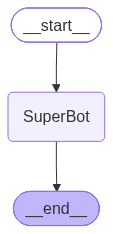

In [12]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile()


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [13]:
## Invocation

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"})

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='8434f1ee-146d-47f3-8ae4-e70a7fe3945c'),
  AIMessage(content="Hello Krish! 👋 Nice to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, T20s, or maybe you enjoy playing yourself? I'd love to hear more about what you like about cricket!", additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Probably they are greeting. We should respond politely, maybe ask about cricket preferences. No disallowed content. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 112, 'prompt_tokens': 82, 'total_tokens': 194, 'completion_time': 0.233963037, 'completion_tokens_details': {'reasoning_tokens': 41}, 'prompt_time': 0.003801328, 'prompt_tokens_details': None, 'queue_time': 0.212104789, 'total_time': 0.237764365}, 'model_name': 'openai/gpt-os

#### Streaming The responses

In [14]:
for event in graph_builder.stream({"messages":"Hello My name is KRish"}):
    print(event)

{'SuperBot': {'messages': [AIMessage(content='Hello, Krish! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hello My name is KRish". Likely they want a greeting. We should respond politely, maybe ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 77, 'total_tokens': 137, 'completion_time': 0.123929863, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.003198775, 'prompt_tokens_details': None, 'queue_time': 0.399031007, 'total_time': 0.127128638}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_9241e9962b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1724f-feff-72d2-acc4-acbcc6322cda-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens': 60, 'total_tokens': 137, 'output_token_details': {'reasoning': 34}})]}}
